<a href="https://colab.research.google.com/github/Himanshu2007-Maurya/infotact_project2/blob/main/ml/notebooks/TerraSpectra_Day02_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
PROJECT_NAME = "TerraSpectra"
DAY = 2
DATASET_NAME = "Apple Fire Blight Hyperspectral Dataset"

print("Project:", PROJECT_NAME)
print("Day:", DAY)
print("Dataset:", DATASET_NAME)

Project: TerraSpectra
Day: 2
Dataset: Apple Fire Blight Hyperspectral Dataset


In [2]:
!pip install -q spectral rasterio scipy scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spectral
import rasterio

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("Selected device:", device)

PyTorch: 2.14.1+cu130
GPU available: True
Selected device: cuda


In [6]:
import spectral

hdr_path = "/content/REFLECTANCE_2047.hdr"

img = spectral.open_image(hdr_path)

print("Image dimensions:", img.shape)
print("Number of spectral bands:", img.nbands)
print("Metadata:")
print(img.metadata)

Image dimensions: (512, 512, 204)
Number of spectral bands: 204
Metadata:
{'description': 'Data recorded with Specim IQ', 'samples': '512', 'lines': '512', 'bands': '204', 'header offset': '0', 'file type': 'ENVI', 'data type': '4', 'interleave': 'BIL', 'sensor type': 'SPECIM IQ', 'byte order': '0', 'default bands': ['70', '53', '19'], 'latitude': '0.00000000', 'longitude': '0.00000000', 'acquisition date': '12-07-2022', 'errors': 'none', 'binning': ['1', '1'], 'tint': '20', 'fps': '50', 'wavelength': ['397.32', '400.20', '403.09', '405.97', '408.85', '411.74', '414.63', '417.52', '420.40', '423.29', '426.19', '429.08', '431.97', '434.87', '437.76', '440.66', '443.56', '446.45', '449.35', '452.25', '455.16', '458.06', '460.96', '463.87', '466.77', '469.68', '472.59', '475.50', '478.41', '481.32', '484.23', '487.14', '490.06', '492.97', '495.89', '498.80', '501.72', '504.64', '507.56', '510.48', '513.40', '516.33', '519.25', '522.18', '525.10', '528.03', '530.96', '533.89', '536.82', '5

In [7]:
hyperspectral_data = img.load()

print("Data shape:", hyperspectral_data.shape)
print("Data type:", hyperspectral_data.dtype)
print("Minimum value:", hyperspectral_data.min())
print("Maximum value:", hyperspectral_data.max())

Data shape: (512, 512, 204)
Data type: float32
Minimum value: 0.0
Maximum value: 2.138675


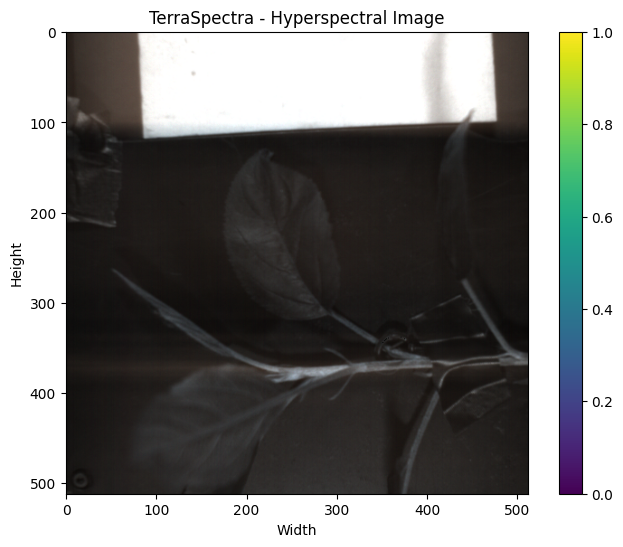

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.imshow(hyperspectral_data[:, :, :3])

plt.title("TerraSpectra - Hyperspectral Image")
plt.xlabel("Width")
plt.ylabel("Height")
plt.colorbar()

plt.show()

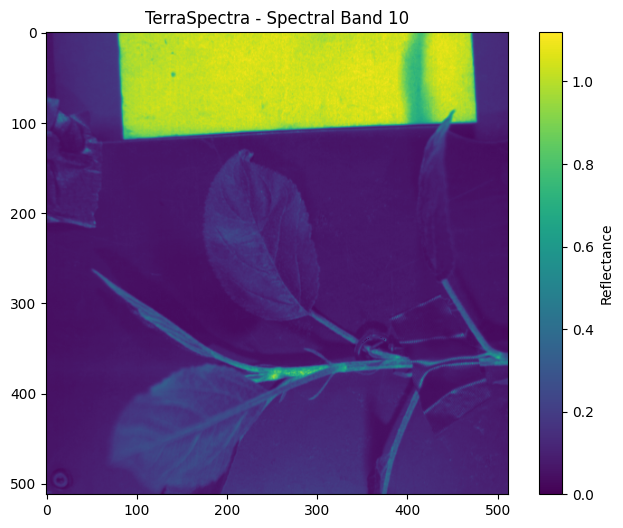

In [9]:
band_number = min(10, img.nbands - 1)

plt.figure(figsize=(8, 6))

plt.imshow(hyperspectral_data[:, :, band_number],
           cmap="viridis")

plt.title(f"TerraSpectra - Spectral Band {band_number}")
plt.colorbar(label="Reflectance")

plt.show()

In [11]:
import numpy as np
import matplotlib.pyplot as plt

pixel_spectrum = np.asarray(
    hyperspectral_data[50, 50, :]
).reshape(-1)

print("Pixel spectrum shape:", pixel_spectrum.shape)
print("Number of spectral values:", len(pixel_spectrum))

Pixel spectrum shape: (204,)
Number of spectral values: 204


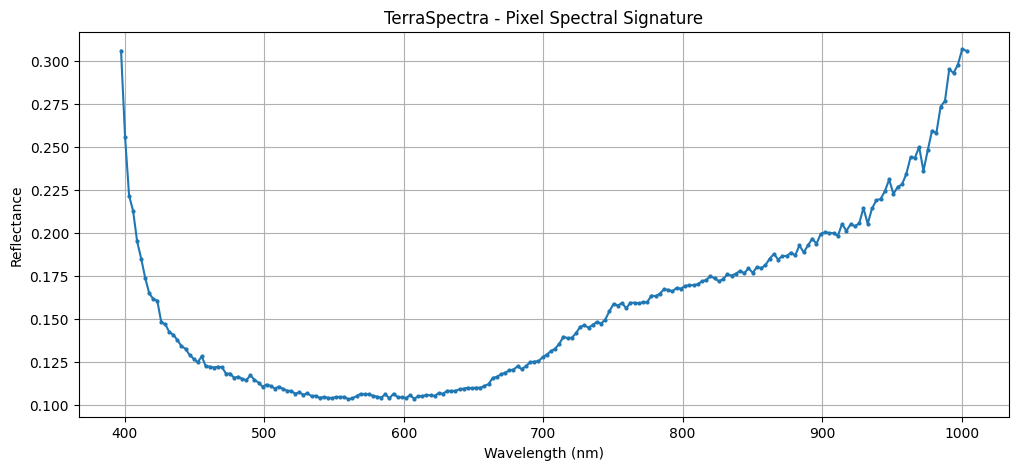

In [12]:
wavelengths = np.array(
    img.metadata['wavelength'],
    dtype=float
)

plt.figure(figsize=(12, 5))

plt.plot(
    wavelengths,
    pixel_spectrum,
    marker='o',
    markersize=2
)

plt.title("TerraSpectra - Pixel Spectral Signature")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance")
plt.grid(True)

plt.show()

In [15]:
print("Hyperspectral data shape:", hyperspectral_data.shape)

data = np.asarray(hyperspectral_data).squeeze()

print("Shape after squeeze:", data.shape)

Hyperspectral data shape: (512, 512, 204)
Shape after squeeze: (512, 512, 204)


RGB image shape: (512, 512, 3)


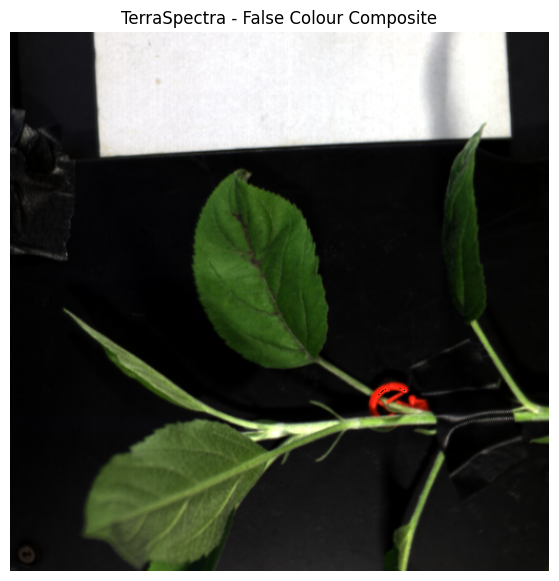

In [16]:
# Ensure the hyperspectral data has 3 dimensions
data = np.asarray(hyperspectral_data).squeeze()

# Verify dimensions
assert data.ndim == 3, f"Unexpected data shape: {data.shape}"

# Ensure spectral bands are in the last dimension
if data.shape[-1] != 204 and data.shape[0] == 204:
    data = np.moveaxis(data, 0, -1)

assert data.shape[-1] == 204, f"Unexpected spectral dimension: {data.shape}"

# Select RGB bands
rgb = np.stack([
    data[:, :, 69],
    data[:, :, 52],
    data[:, :, 18]
], axis=-1).astype(np.float32)

# Normalize each channel
for i in range(3):
    band = rgb[:, :, i]
    low, high = np.percentile(band, [2, 98])

    rgb[:, :, i] = np.clip(
        (band - low) / (high - low + 1e-8),
        0, 1
    )

print("RGB image shape:", rgb.shape)

# Display
plt.figure(figsize=(9, 7))
plt.imshow(rgb)
plt.title("TerraSpectra - False Colour Composite")
plt.axis("off")
plt.show()

In [17]:
# Dataset Quality Assessment

print("DATASET QUALITY REPORT")
print("-" * 40)

print("Shape:", data.shape)
print("Data type:", data.dtype)

print("Minimum:", np.nanmin(data))
print("Maximum:", np.nanmax(data))
print("Mean:", np.nanmean(data))
print("Standard deviation:", np.nanstd(data))

print("NaN values:", np.isnan(data).sum())
print("Infinite values:", np.isinf(data).sum())

print("Zero values:", np.sum(data == 0))

print("Total pixels:", data.shape[0] * data.shape[1])
print("Total spectral bands:", data.shape[2])

DATASET QUALITY REPORT
----------------------------------------
Shape: (512, 512, 204)
Data type: float32
Minimum: 0.0
Maximum: 2.138675
Mean: 0.31681615
Standard deviation: 0.39031953
NaN values: 0
Infinite values: 0
Zero values: 1428
Total pixels: 262144
Total spectral bands: 204


In [18]:
# Analyze individual spectral bands

band_statistics = []

for i in range(data.shape[2]):

    band = data[:, :, i]

    band_statistics.append({
        "Band": i + 1,
        "Minimum": np.nanmin(band),
        "Maximum": np.nanmax(band),
        "Mean": np.nanmean(band),
        "Std": np.nanstd(band)
    })

band_df = pd.DataFrame(band_statistics)

display(band_df.head(10))

,Band,Minimum,Maximum,Mean,Std
0,1,0.0,1.118518,0.284737,0.322771
1,2,0.0,1.116279,0.274024,0.328094
2,3,0.0,1.113744,0.267028,0.329901
3,4,0.0,1.116935,0.261675,0.331656
4,5,0.0,1.114983,0.258484,0.332262
5,6,0.0,1.120370,0.256999,0.333665
6,7,0.0,1.118785,0.255392,0.334546
7,8,0.0,1.115000,0.254013,0.335160
8,9,0.0,1.111617,0.253291,0.335815
9,10,0.0,1.116910,0.252753,0.336485


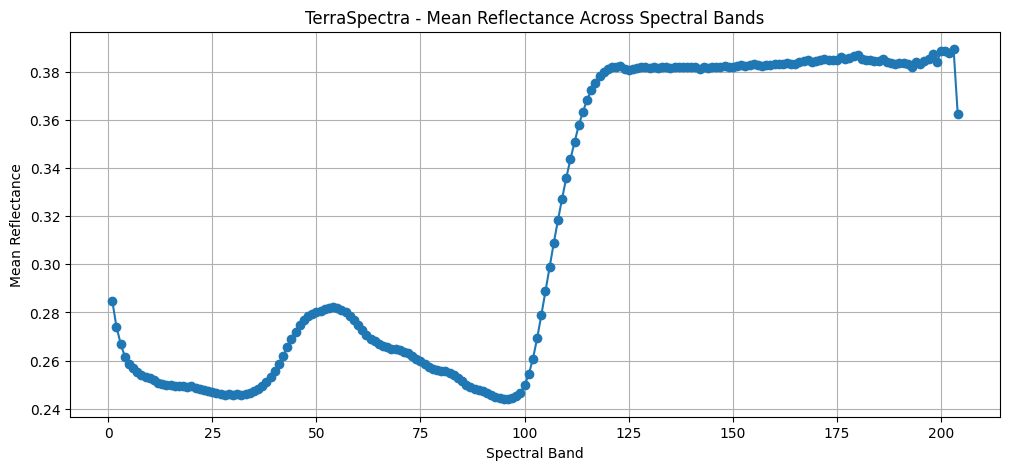

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    band_df["Band"],
    band_df["Mean"],
    marker="o"
)

plt.title("TerraSpectra - Mean Reflectance Across Spectral Bands")
plt.xlabel("Spectral Band")
plt.ylabel("Mean Reflectance")
plt.grid(True)

plt.show()

In [20]:
# Day 2: Hyperspectral Data Normalization

import numpy as np

# Preserve original data
original_data = hyperspectral_data.copy()

# Calculate mean and standard deviation for each band
band_mean = np.mean(original_data, axis=(0, 1))
band_std = np.std(original_data, axis=(0, 1))

# Avoid division by zero
band_std[band_std == 0] = 1

# Apply Z-score normalization
normalized_data = (
    original_data - band_mean.reshape(1, 1, -1)
) / band_std.reshape(1, 1, -1)

print("Normalization completed!")
print("Original shape:", original_data.shape)
print("Normalized shape:", normalized_data.shape)
print("Normalized mean:", np.mean(normalized_data))
print("Normalized standard deviation:", np.std(normalized_data))
print("Data type:", normalized_data.dtype)

Normalization completed!
Original shape: (512, 512, 204)
Normalized shape: (512, 512, 204)
Normalized mean: -3.6146128e-05
Normalized standard deviation: 1.0000082
Data type: float32


In [21]:
# Save normalized hyperspectral data

np.save(
    "TerraSpectra_Normalized_Data.npy",
    normalized_data
)

print("Normalized dataset saved successfully!")

Normalized dataset saved successfully!


In [22]:
import numpy as np
import os

# Create output directory
os.makedirs("processed_data", exist_ok=True)

# Save normalized hyperspectral cube
np.save(
    "processed_data/normalized_hyperspectral_data.npy",
    normalized_data
)

print("Normalized dataset saved successfully!")
print("Saved shape:", normalized_data.shape)
print("File size:", round(
    os.path.getsize(
        "processed_data/normalized_hyperspectral_data.npy"
    ) / (1024**2), 2
), "MB")

Normalized dataset saved successfully!
Saved shape: (512, 512, 204)
File size: 204.0 MB


In [23]:
loaded_data = np.load(
    "processed_data/normalized_hyperspectral_data.npy"
)

print("Loaded shape:", loaded_data.shape)
print("Mean:", np.mean(loaded_data))
print("Standard deviation:", np.std(loaded_data))

assert loaded_data.shape == (512, 512, 204)

print("Dataset verification successful!")

Loaded shape: (512, 512, 204)
Mean: -3.6146128e-05
Standard deviation: 1.0000082
Dataset verification successful!
